Data Preperation for Gallstone Data

In [2]:
import os
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

Stage 1 : Load the data

In [3]:
#CELL 2:

#df is a pandas table, works like an excel sheet. 
#turned the excel work sheet from 'Strict Open XML Spredsheet' to 'Exel Workbook'
df = pd.read_excel('Data/dataset-uci-fixed.xlsx')

#step 1: count rows and columns
df.shape

(319, 39)

In [4]:
#CELL 3:

# first 5 rows, to check the numbers look sensible
df.head()

#first 5 rows
df.info()

#lists every columns, its data type and how many non-empty values it has. 
#this is the main "data quality check" tool
df.columns

<class 'pandas.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                          319 no

Index(['Gallstone Status', 'Age', 'Gender', 'Comorbidity',
       'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia',
       'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)',
       'Total Body Water (TBW)', 'Extracellular Water (ECW)',
       'Intracellular Water (ICW)',
       'Extracellular Fluid/Total Body Water (ECF/TBW)',
       'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
       'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
       'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
       'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
       'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
       'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
       'High Density Lipoprotein (HDL)', 'Triglyceride',
       'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
       'Alkaline Phosphatase (ALP)', 'Creatinine',
       'Glomerular Filtration Rate (GFR

In [5]:
# builds a new table from three pieces of informatino, one row per column of df
# df.dtypes = the data types of each column
# df.min() / df.max() = the smallest and largest value in each column
column_types = df.dtypes
column_mins = df.min()
column_maxs = df.max()

summary = pd.DataFrame({'Type': column_types, 'Min': column_mins, 'Max': column_maxs})

#writng the name on its own line makes the notebook display it
summary

,Type,Min,Max
Gallstone Status,int64,0.00,1.00
Age,int64,20.00,96.00
Gender,int64,0.00,1.00
Comorbidity,int64,0.00,3.00
Coronary Artery Disease (CAD),int64,0.00,1.00
Hypothyroidism,int64,0.00,1.00
Hyperlipidemia,int64,0.00,1.00
Diabetes Mellitus (DM),int64,0.00,1.00
Height,int64,145.00,191.00
Weight,float64,42.90,143.50


In [6]:
#CELL 4:

# df.copy() makes a real second table. without it, raw and df would be two names
# for the same table, and every change i make to df would silently change raw too
raw = df.copy()

In [7]:
#CELL 5:

# make the folder where the files will be saved
# exist_ok=True means: don't crash if the folder already exists
os.makedirs('processed', exist_ok=True)
os.getcwd() 

'/Users/henriettesele/Documents/DAT305/prosjekt/GallStone_Project'

Stage 2 : Rename and group the columns

In [8]:
#CELL 6:

# remove stray spaces from the header names
# str.strip() cuts spaces at the start and end of every column
df.columns = df.columns.str.strip()

In [9]:
#CELL 7:

# a dictionary {'old' : 'new' } is a lookup table
rename_map = {
    'Gallstone Status': 'Gallstone_Status',
    'Age': 'Age',
    'Gender': 'Gender',
    'Comorbidity': 'Comorbidity',
    'Coronary Artery Disease (CAD)': 'CAD',
    'Hypothyroidism': 'Hypothyroidism',
    'Hyperlipidemia': 'Hyperlipidemia',
    'Diabetes Mellitus (DM)': 'DM',
    'Height': 'Height',
    'Weight': 'Weight',
    'Body Mass Index (BMI)': 'BMI',
    'Total Body Water (TBW)': 'TBW',
    'Extracellular Water (ECW)': 'ECW',
    'Intracellular Water (ICW)': 'ICW',
    'Extracellular Fluid/Total Body Water (ECF/TBW)': 'ECF_TBW',
    'Total Body Fat Ratio (TBFR) (%)': 'TBFR',
    'Lean Mass (LM) (%)': 'LM',
    'Body Protein Content (Protein) (%)': 'Protein',
    'Visceral Fat Rating (VFR)': 'VFR',
    'Bone Mass (BM)': 'BM',
    'Muscle Mass (MM)': 'MM',
    'Obesity (%)': 'Obesity',
    'Total Fat Content (TFC)': 'TFC',
    'Visceral Fat Area (VFA)': 'VFA',
    'Visceral Muscle Area (VMA) (Kg)': 'VMA',
    'Hepatic Fat Accumulation (HFA)': 'HFA',
    'Glucose': 'Glucose',
    'Total Cholesterol (TC)': 'TC',
    'Low Density Lipoprotein (LDL)': 'LDL',
    'High Density Lipoprotein (HDL)': 'HDL',
    'Triglyceride': 'Triglyceride',
    'Aspartat Aminotransferaz (AST)': 'AST',
    'Alanin Aminotransferaz (ALT)': 'ALT',
    'Alkaline Phosphatase (ALP)': 'ALP',
    'Creatinine': 'Creatinine',
    'Glomerular Filtration Rate (GFR)': 'GFR',
    'C-Reactive Protein (CRP)': 'CRP',
    'Hemoglobin (HGB)': 'HGB',
    'Vitamin D': 'VitaminD',
    }

# build the reverse lookup: short name -> full name
# (we need it later so the report can spell out the full clinical names)
short_to_full = {}
for full_name, short_name in rename_map.items():
    short_to_full[short_name] = full_name

# apply the new names
df = df.rename(columns=rename_map)

# should now print 39 short names
df.columns.tolist()

['Gallstone_Status',
 'Age',
 'Gender',
 'Comorbidity',
 'CAD',
 'Hypothyroidism',
 'Hyperlipidemia',
 'DM',
 'Height',
 'Weight',
 'BMI',
 'TBW',
 'ECW',
 'ICW',
 'ECF_TBW',
 'TBFR',
 'LM',
 'Protein',
 'VFR',
 'BM',
 'MM',
 'Obesity',
 'TFC',
 'VFA',
 'VMA',
 'HFA',
 'Glucose',
 'TC',
 'LDL',
 'HDL',
 'Triglyceride',
 'AST',
 'ALT',
 'ALP',
 'Creatinine',
 'GFR',
 'CRP',
 'HGB',
 'VitaminD']

In [10]:
#CELL 8:

# name the target once, so i never mistaype it again
target = 'Gallstone_Status'

# features = every column except the target
features = []
for col in df.columns:
    if col != target:
        features.append(col) # every column except the target

# should print 38
len(features)

38

In [11]:
#CELL 9:

# put every feature in a clinical group
#the clinical groups
groups = {
    'demographic': ['Age', 'Gender', 'Height', 'Weight', 'BMI'],
    
    # the rest that fit yes/no
    'comorbidity': ['Comorbidity', 'CAD', 'Hypothyroidism', 
                    'Hyperlipidemia', 'DM'],
    #15 body-composition columns
    'bioimpedance': ['TBW', 'ECW', 'ICW', 'ECF_TBW', 'TBFR', 'LM', 'Protein', 
                     'VFR', 'BM', 'MM', 'Obesity', 'TFC', 'VFA', 'VMA', 'HFA'],
    # 13 bloodtests 
    'laboratory': ['Glucose', 'TC', 'LDL', 'HDL', 'Triglyceride', 'AST', 
                   'ALT', 'ALP', 'Creatinine', 'GFR', 'CRP', 'HGB', 'VitaminD'],
}


In [12]:
#CELL 10: SANITY CHECK!!!

# step 1: collect every name that appears in any group into one list
assigned = []
for groups_name, names in groups.items():
    for name in names:
        assigned.append(name)

# step 2: features I forgot to put in a group
forgotten = []
for feature in features:
    if feature not in assigned:
        forgotten.append(feature)
print('Forgotten features:', forgotten)

# step 3: names in the groups that are not real columns, 
# as in typos (should print [])
typos = []
for name in assigned:
    if name not in features:
        typos.append(name)
print('Typos in groups:', typos)

Forgotten features: []
Typos in groups: []


In [13]:
#CELL 11: turn the groups into a table, one row per feature

# create an empty list
rows = []
for groups_name, feats in groups.items():
    for feat in feats:
        rows.append([feat, groups_name, short_to_full[feat]]) #one row per feature

feature_groups = pd.DataFrame(rows, columns=['feature', 'group', 'full_name'])

# expecting 15 bioimpedance, 13 labs, 5 and 5
feature_groups['group'].value_counts()

group
bioimpedance    15
laboratory      13
demographic      5
comorbidity      5
Name: count, dtype: int64

Stage 3: Exploring before touching anything

Gallstone_Status uses UCI coding: 
0 = has gallstones, 1 = no gallstones

Gallstone_Status
0    161
1    158
Name: count, dtype: int64


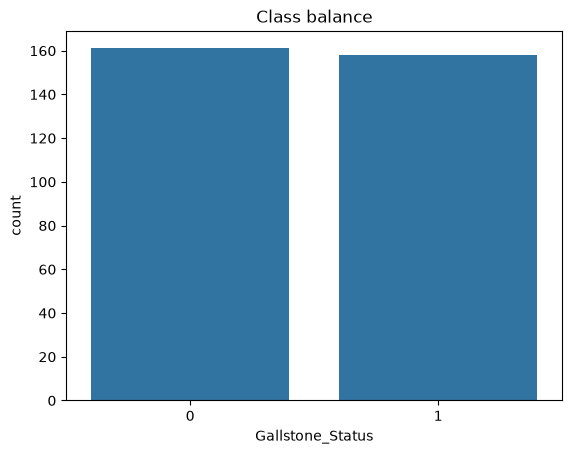

In [14]:
# 3a. class balance: how many patients with /wihtout gallstones?
#expect 0 = has gallstones -> 161, 1 = none ->158
print (df[target].value_counts())

#prportions(about 0.5/0.5)
df[target].value_counts(normalize=True)

sns.countplot(x=target, data=df)
plt.title('Class balance')
plt.show()

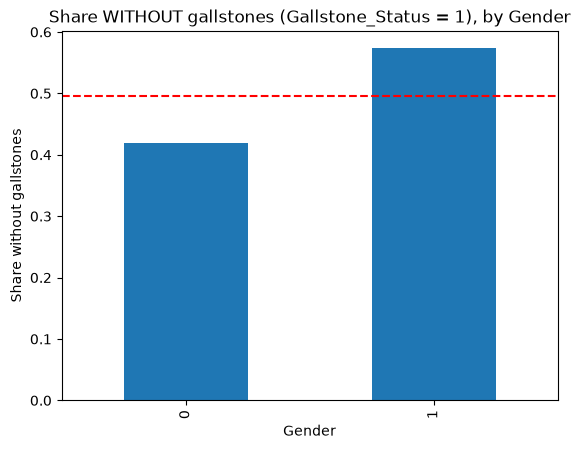

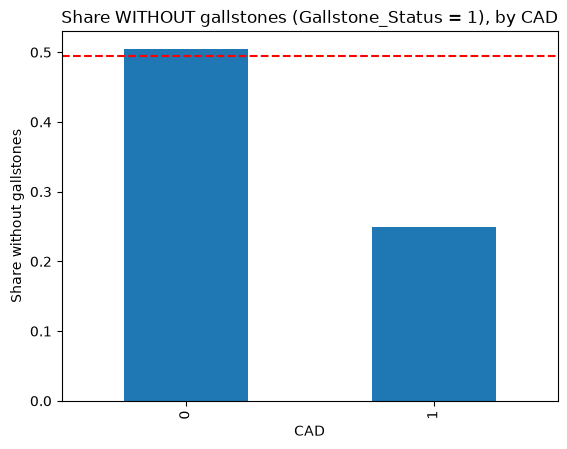

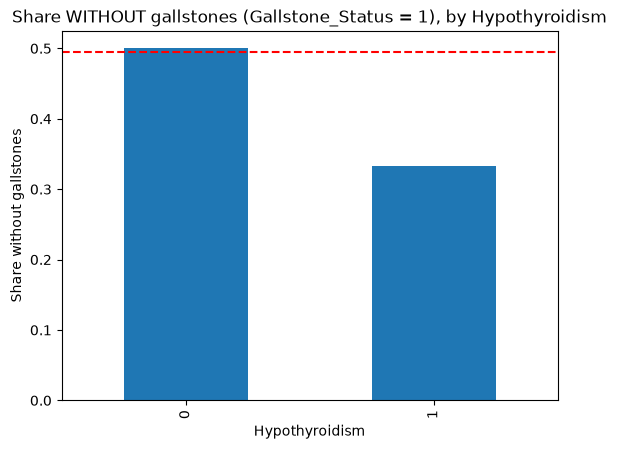

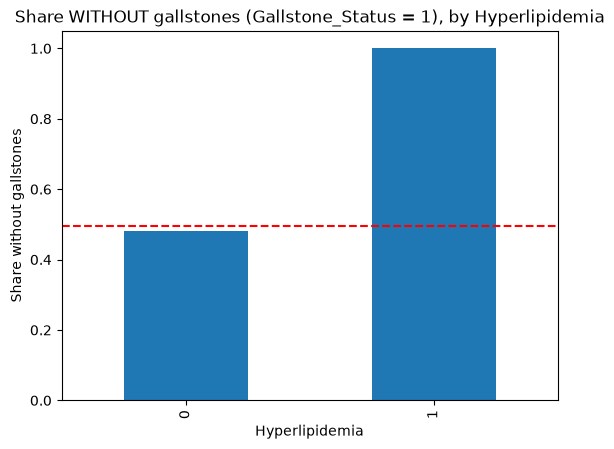

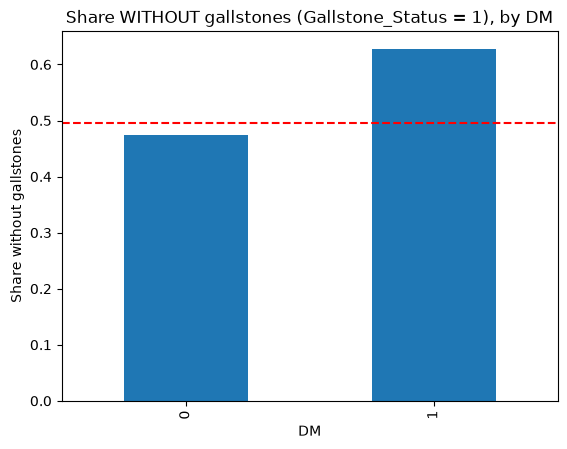

In [15]:
# 3b. which yes/no flags move the outcome?

binary_cols = ['Gender', 'CAD', 'Hypothyroidism', 'Hyperlipidemia', 'DM']

# the targer is 0/1, so its mean = the share of rows equal to 1
overall = df[target].mean()

# repeat the block below once per column
for col in binary_cols:
    
    # group rows by o/1 in this column, average the target in each group
    rates = df.groupby(col)[target].mean()
    
    # bar chart of those two averages
    rates.plot(kind='bar')
    
    # dashed line = the overall average, for comparison
    plt.axhline(overall, linestyle='--', color='red')

    #f'...{col} inserts the column name
    plt.title(f'Share WITHOUT gallstones (Gallstone_Status = 1), by {col}')
    plt.ylabel('Share without gallstones')
    plt.show()

In [16]:
# 3c. how many patients is each rate based on?

# crosstab counts rows for every combination of two columnms
columns_to_count = binary_cols + ['Comorbidity', 'HFA'] #+ joins two lists into one

for col in columns_to_count: 
    print(pd.crosstab(df[col], df[target]))
    print()


Gallstone_Status   0   1
Gender                  
0                 94  68
1                 67  90

Gallstone_Status    0    1
CAD                       
0                 152  155
1                   9    3

Gallstone_Status    0    1
Hypothyroidism            
0                 155  155
1                   6    3

Gallstone_Status    0    1
Hyperlipidemia            
0                 161  150
1                   0    8

Gallstone_Status    0    1
DM                        
0                 145  131
1                  16   27

Gallstone_Status    0    1
Comorbidity               
0                 108  109
1                  50   49
2                   1    0
3                   2    0

Gallstone_Status   0   1
HFA                     
0                 67  62
1                 33   8
2                 47  75
3                 13  13
4                  1   0



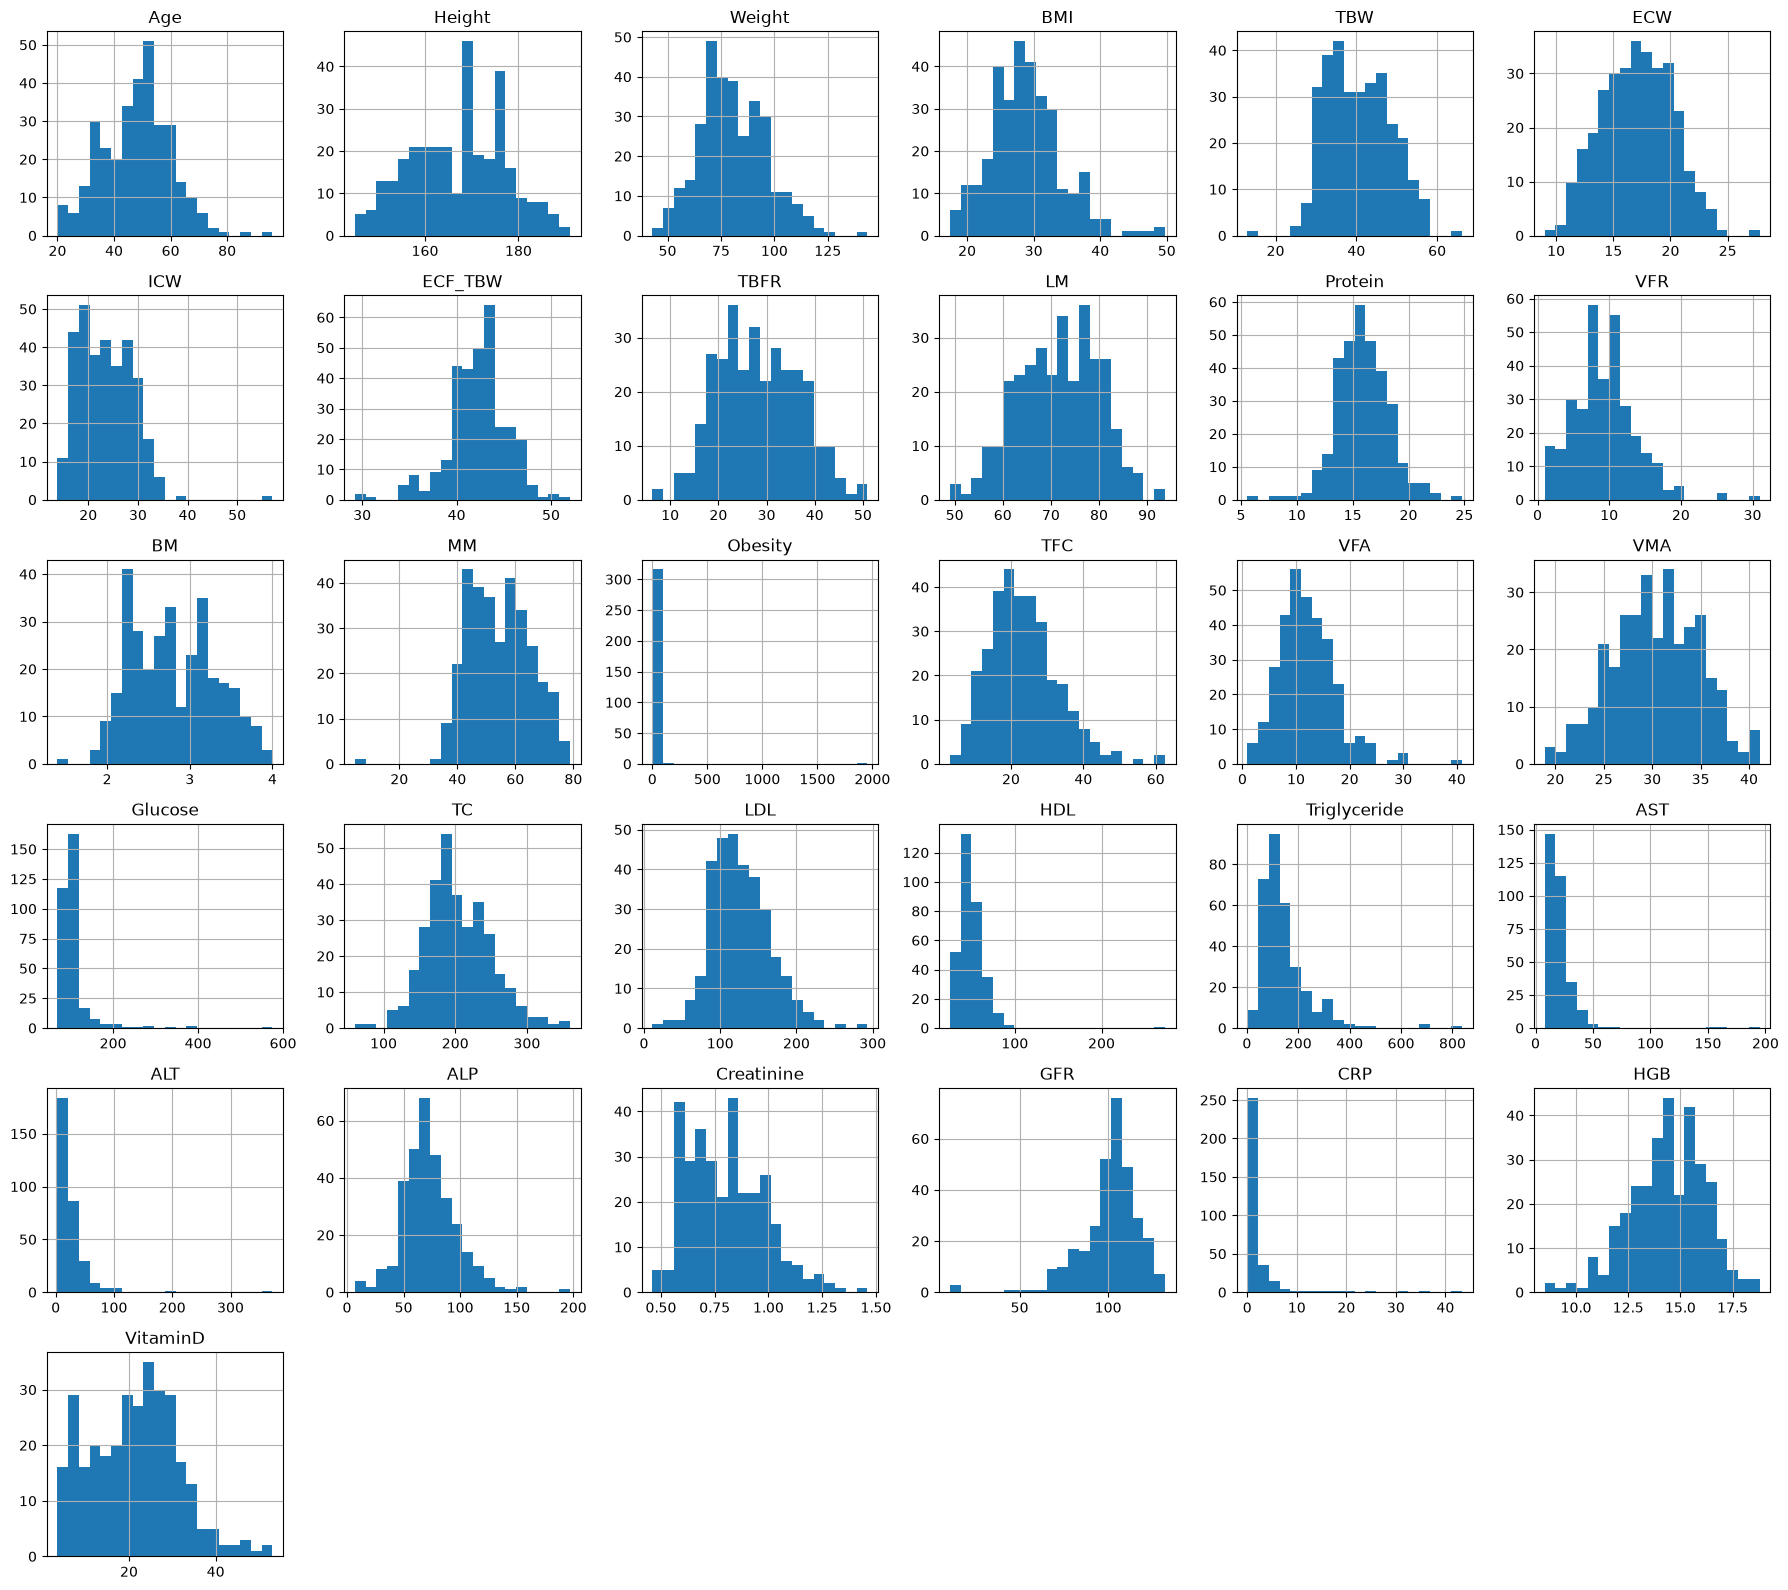

Obesity         16.873233
ALT              7.276949
AST              6.994506
HDL              6.528948
Glucose          5.937810
CRP              5.411104
Triglyceride     2.786394
VFA              1.057540
GFR             -1.812975
dtype: float64

In [17]:
# 3d. what does each continous feature look like?

# the 7 columns that are reall categories or flags, not measurments
categorical = ['Gender', 'Comorbidity', 'CAD', 
                    'Hypothyroidism', 'Hyperlipidemia', 'DM', 'HFA']

# continuous = every feature that is NOT in the categorical list
continuous = []
for col in features:
    if col not in categorical:
        continuous.append(col)

len(continuous)

# one histogram per feature: x = value, y = how many patients
df[continuous].hist(bins=20, figsize=(18, 16))
#stops the small plots  from overlapping
plt.tight_layout()

plt.show()

# shew = how lopsided a distribution is.
# 0 = symmetric, big positive = a long tail to the right
skew_values = df[continuous].skew()
skew_values = skew_values.sort_values(ascending=False)

#show onlu the strongly lopsided ones
strongly_skewed = skew_values[skew_values.abs() > 1]
strongly_skewed

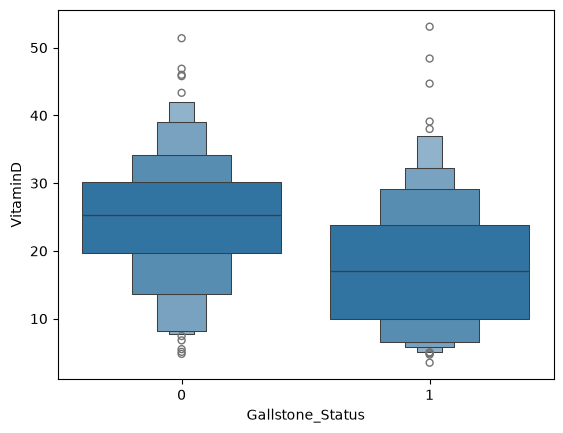

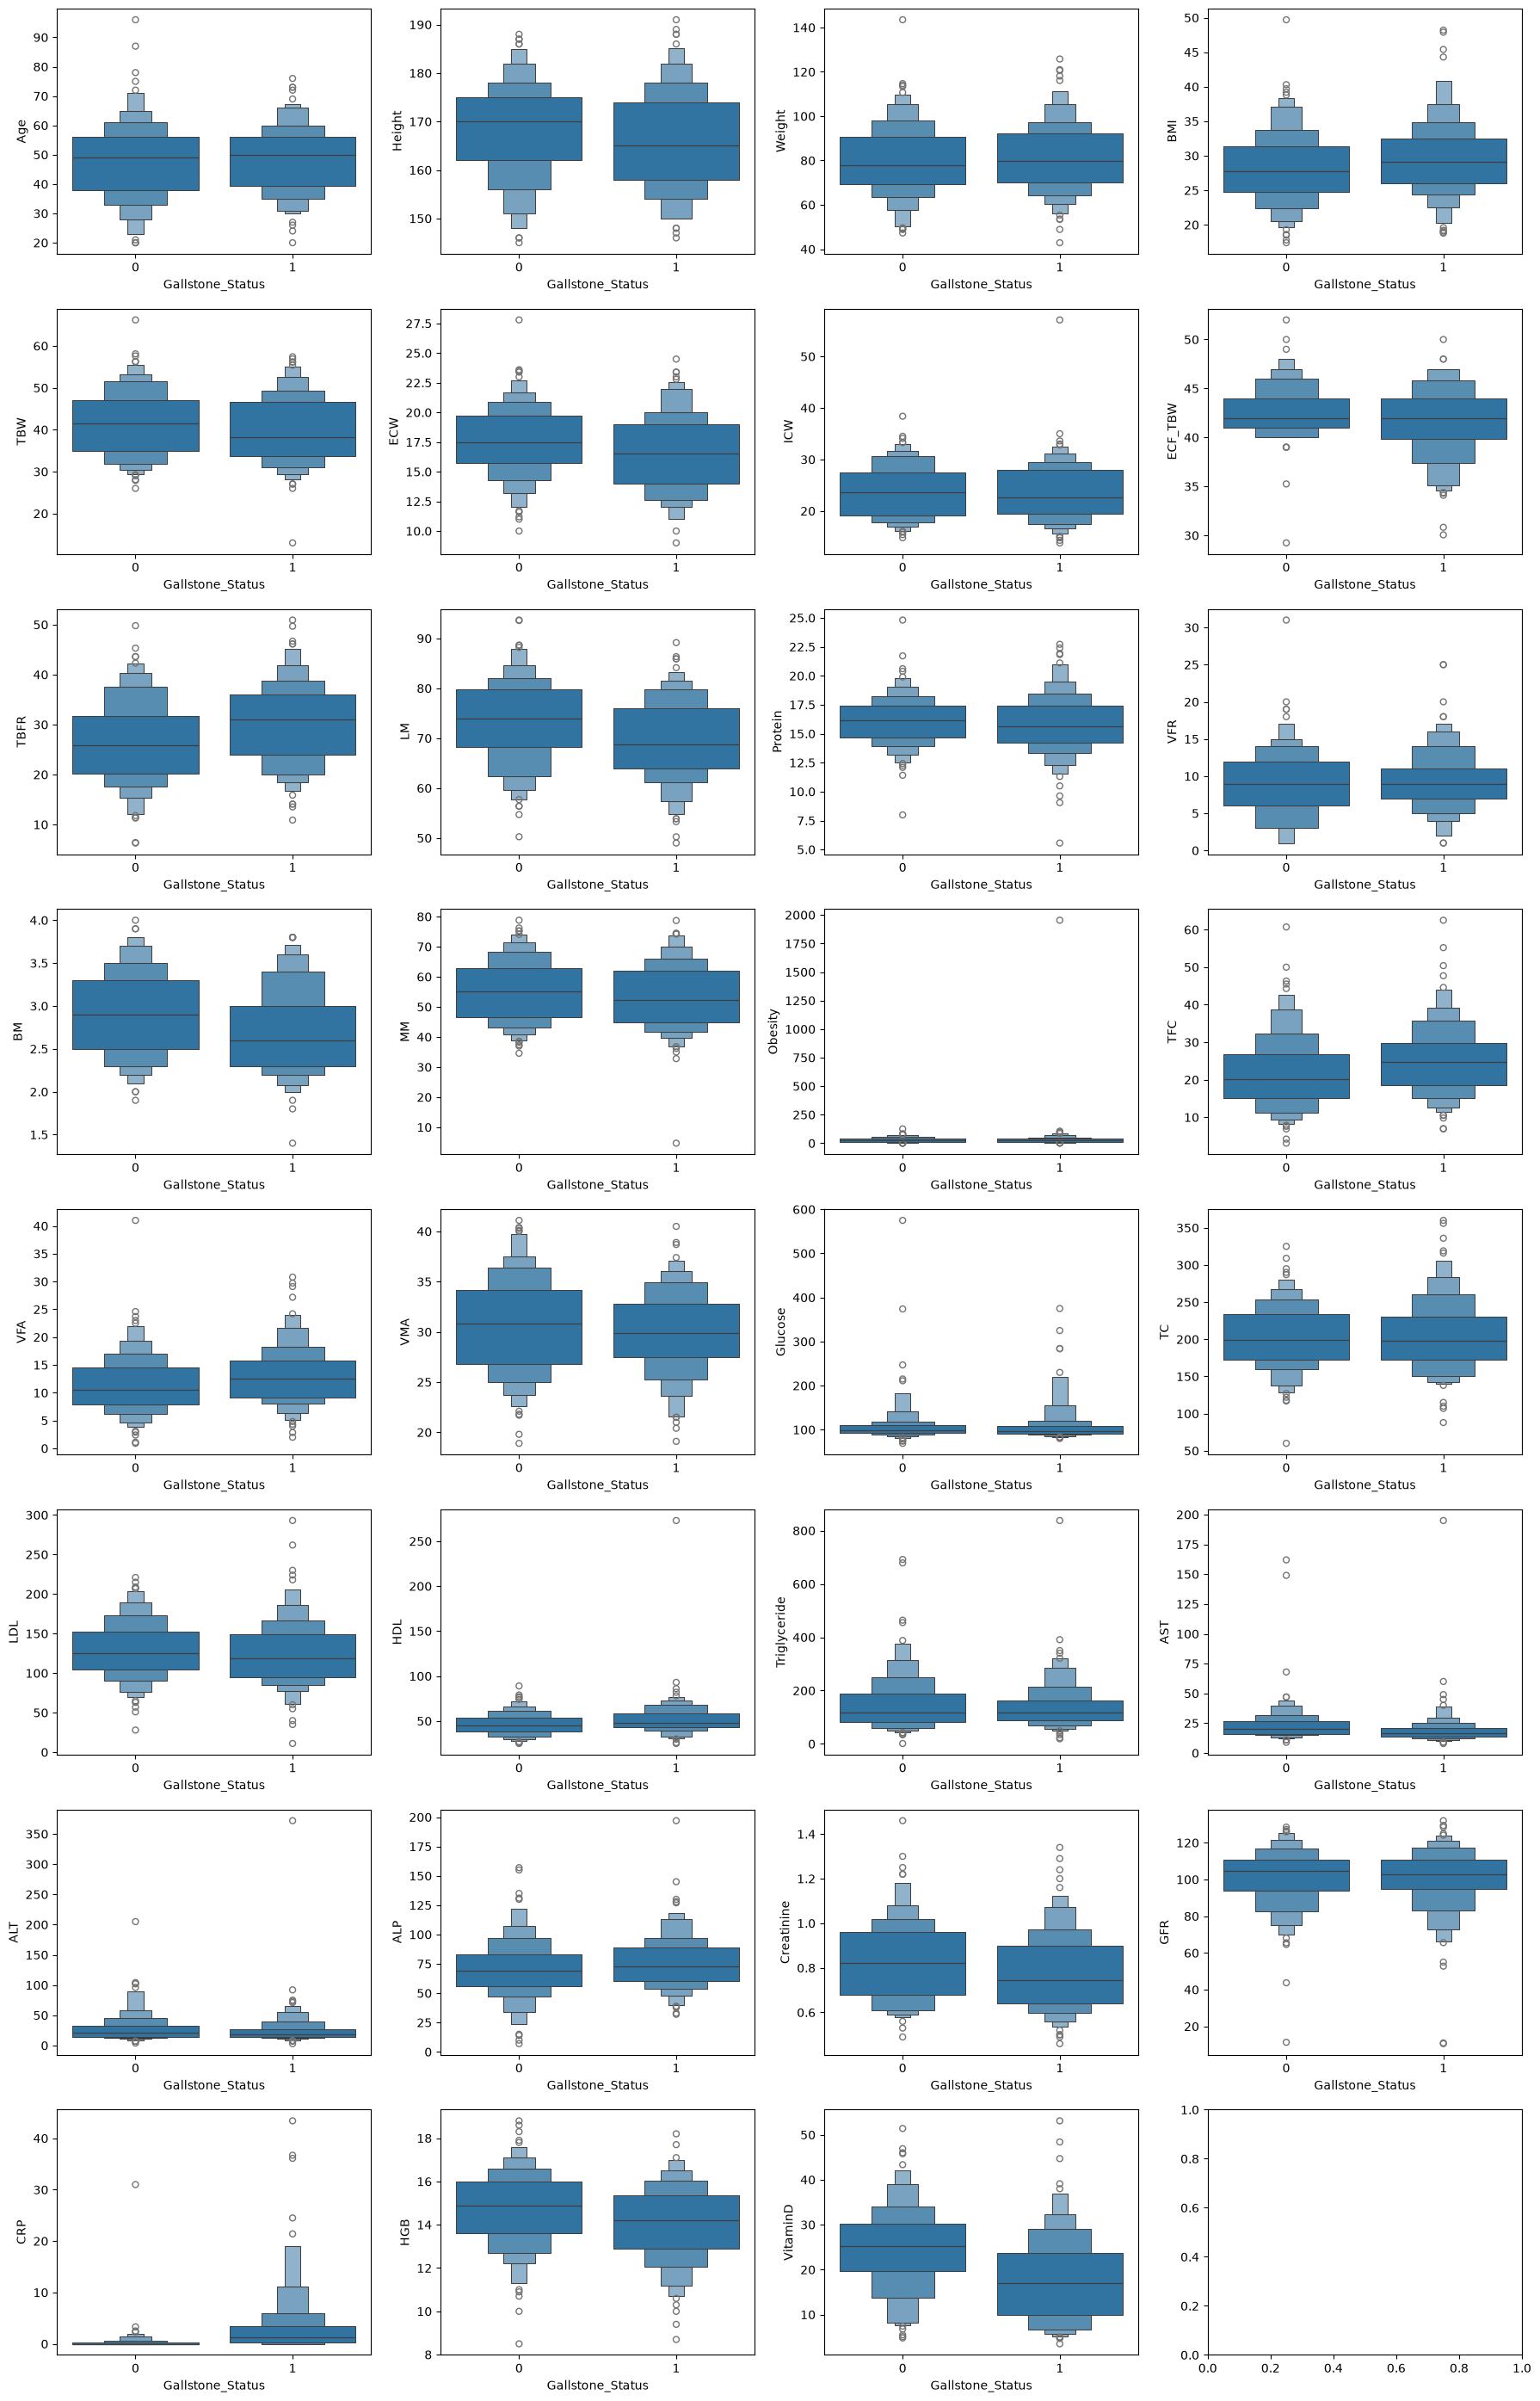

VitaminD   -0.354873
LM         -0.225749
BM         -0.216570
HGB        -0.196872
ECW        -0.178436
dtype: float64
HDL               0.158622
Hyperlipidemia    0.161901
TFC               0.170158
TBFR              0.225470
CRP               0.281995
dtype: float64


In [18]:
#3e.  which features separate the two classes?

# a boxplot of one feature, split by class: 
# the box is the middle 50% of patients, the line is the median
sns.boxenplot(x=target, y='VitaminD', data=df)
plt.show()

#the same for all 31 continous features in a grid (8 row x 4 columns = 32 panels
# the last stays empty)
fig, axes = plt.subplots(8, 4, figsize=(18, 28))
# turn the 8x4 grid into one long list of panels
all_panels = axes.flatten()


for feature_number in range(len(continuous)):
    col = continuous[feature_number] 
    panel = all_panels[feature_number]
    sns.boxenplot(x=target, y=col, data=df, ax=panel)

plt.tight_layout()
plt.show()

#correlation = a number from -1 to +1 for how two columns move together
#corrwith() comapres every feature against the target in one go
corr_with_target = df[features].corrwith(df[target])
corr_with_target = corr_with_target.sort_values()

# 5 most negative
print(corr_with_target.head(5))
# 5 most postive
print(corr_with_target.tail(5))




In [19]:
# 3f. whih features are near duplicates?

#table of every feature vs every other; abs() drops the sign
corr = df[features].corr()
corr = corr.abs()

# an empty list to be filled in
pairs = []

# goes through the table, one pair of colums at a time
for row_number in range(len(corr.columns)):
    # j starts after i, so each pair is seen once.
    for column_number in range (row_number + 1, len(corr.columns)):
        # iloc[row, column] pics one cell by postion
        value = corr.iloc[row_number, column_number]

        if value > 0.85:
            first_feature = corr.columns[row_number]
            second_feature = corr.columns[column_number]
            pairs.append([first_feature, second_feature, value])


collinear_pairs = pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'abs_corr'])
collinear_pairs = collinear_pairs.sort_values('abs_corr', ascending=False)

collinear_pairs

,feature_1,feature_2,abs_corr
6,TBFR,LM,0.994055
3,TBW,MM,0.928633
2,TBW,ECW,0.904351
5,ICW,MM,0.904088
1,BMI,TFC,0.902706
0,Weight,VFA,0.881509
10,TFC,VFA,0.873628
7,TBFR,TFC,0.866062
11,TC,LDL,0.865821
4,ECW,MM,0.865198


Stage 4: Cleaning the data, and justy every decision

In [20]:
# 4a. Duplicates and Missing Values

#rows identical to an earlier row
print(df.duplicated().sum())

#same measurments ignoring the label
print(df[features].duplicated().sum())

#total number of empty cells in the whole table
empty_per_column = df.isnull().sum()
print(empty_per_column.sum())


0
0
0


In [21]:
# 4b. Hidden missing values; zeros
# "no empty cells" does not mean "no missing data"

# == 0 gives True/False per cell; sum() counts the Trues
is_zeros = (df[features] == 0)

# count the Trues in each column
zero_counts = is_zeros.sum()

# keep only the columns that contain at least one zero
zero_counts = zero_counts[zero_counts > 0]
zero_counts = zero_counts.sort_values(ascending=False)

print(zero_counts)

Hyperlipidemia    311
Hypothyroidism    310
CAD               307
DM                276
Comorbidity       217
Gender            162
HFA               129
CRP               125
dtype: int64


In [22]:
#4c. CRP zeros: keep them and add a flag

# True/False: is CRP exactly 0 for this patient?
crp_is_zero = (df['CRP'] == 0)

# True/False -> 1/0, stored as a new column
df['CRP_below_detection'] = crp_is_zero.astype(int)

# how many patients have the flag?
print(df['CRP_below_detection'].sum())


# the table has a new column, so rebuild the features list
features = []
for col in df.columns:
    if col != target:
        features.append(col)


# add the new column to the laboratory group
# (only run this cell once, or the name gets added twice)
groups['laboratory'].append('CRP_below_detection')

# give it a full name
short_to_full['CRP_below_detection'] = 'CRP below detection limit (CRP = 0)'



125


In [23]:
# 4c. continued
# this is cell 11 again, to prevent the need to rerun it later
rows = []
for groups_name, feats in groups.items():
    for feat in feats:
        rows.append([feat, groups_name, short_to_full[feat]])

feature_groups = pd.DataFrame(rows, columns=['feature', 'group', 'full_name'])

len(feature_groups)
print(feature_groups['group'].value_counts())

group
bioimpedance    15
laboratory      14
demographic      5
comorbidity      5
Name: count, dtype: int64


In [24]:
#4d. Near-constant columns: keep them anyway

# how many different values do each feature have?
unique_counts = df[features].nunique()

# any feature with only 1 different vaulue is constant (empty)
constant_features = unique_counts[unique_counts == 1]
print(constant_features)

# share of patients with a 0 in the three rarest flags
rare_flags = df[['CAD', 'Hypothyroidism', 'Hyperlipidemia']]
share_zero = (rare_flags== 0).mean()
print(share_zero)

Series([], dtype: int64)
CAD               0.962382
Hypothyroidism    0.971787
Hyperlipidemia    0.974922
dtype: float64


In [25]:
#4e. outliers in three passes

# PASS 1
q1 = df[continuous].quantile(0.25)  # value 25% of patients fall below
q3 = df[continuous].quantile(0.75)  # value 75% of patients fall below
iqr = q3 - q1                       # the spread of the middle 50%

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

too_low = (df[continuous] < lower_fence)
too_high = (df[continuous] > upper_fence)
is_outlier = too_low | too_high  # | means "or"

# count/sort outliers per column, most first
outlier_counts = is_outlier.sum()
outlier_counts = outlier_counts.sort_values(ascending=False)
print(outlier_counts)


# PASS 2
# delibratly wide bounds: only clearly broken values get caught
bounds = {
    'Age': (18, 100), 
    'Height': (120, 220), 
    'Weight': (30, 250), 
    'BMI': (12, 170), 
    'HGB': (5, 22), 
    'Glucose': (30, 800), 
    'Triglyceride': (10, 2000), 
    'Obesity': (0, 500),
}

#
for col, (low, high) in bounds.items():
    bad = df[(df[col] < low) | (df[col] > high)]
    print(col, '->', len(bad), 'impossible value(s) at index',
    bad.index.tolist())

# PASS 3

# total cholestrol is the sum of its parts, so
# LDL + HDL + Triglyceride/5 - TC should be close to 0
residual = df['LDL'] + df['HDL'] + df['Triglyceride'] / 5 - df['TC']

# the median residula shoulb ne small
print(residual.describe())


#patients where the nuber disagree by more than 40
bad_rows = residual.abs() > 40
bad_lipids = df.loc[bad_rows, ['TC', 'LDL', 'HDL', 'Triglyceride']]
bad_lipids = bad_lipids.copy()
bad_lipids['residual'] = residual[bad_rows].round(1)
bad_lipids

CRP             34
ALT             27
Glucose         25
AST             23
Triglyceride    20
GFR             13
ALP             12
Protein          8
ECF_TBW          7
Obesity          7
TFC              7
BMI              5
TC               5
HDL              5
VFA              5
LDL              4
HGB              3
VFR              3
Creatinine       2
Age              2
TBW              2
Weight           2
VitaminD         2
MM               1
ICW              1
ECW              1
VMA              0
Height           0
BM               0
LM               0
TBFR             0
dtype: int64
Age -> 0 impossible value(s) at index []
Height -> 0 impossible value(s) at index []
Weight -> 0 impossible value(s) at index []
BMI -> 0 impossible value(s) at index []
HGB -> 0 impossible value(s) at index []
Glucose -> 0 impossible value(s) at index []
Triglyceride -> 1 impossible value(s) at index [127]
Obesity -> 1 impossible value(s) at index [239]
count    319.000000
mean       1.533034
s

,TC,LDL,HDL,Triglyceride,residual
4,205.0,154.0,30.0,326.0,44.2
11,259.0,115.0,50.0,206.0,-52.8
20,225.0,128.0,33.0,692.0,74.4
78,214.0,194.0,46.0,128.0,51.6
194,280.0,88.0,30.0,116.0,-138.8
205,240.0,120.0,47.0,150.0,-43.0
218,336.0,177.0,60.0,159.0,-67.2
250,259.0,79.0,41.0,320.0,-75.0
286,181.0,11.0,53.0,162.0,-84.6
318,296.0,155.0,273.0,19.0,135.8


In [26]:
#4f. Fix the one unit error: Triglyceride = 1.39

# (a mmol/L value in a mg/dL column; multiply by 88.57 to convert)
# which rows have a Triglyceride value below 10?
low_trig = df['Triglyceride'] < 10
print(df.loc[low_trig, 'Triglyceride'])

# multiply those values by 88.57
df.loc[low_trig, 'Triglyceride'] = df.loc[low_trig, 'Triglyceride'] * 88.57

# now about 123.1, close to a typical patient
print(df.loc[127, 'Triglyceride'])

127    1.39
Name: Triglyceride, dtype: float64
123.11229999999998


In [27]:
#4g. FLag HDL = 237 but do not change it

# the highest HDL values (273 is far above the next one, 93)
print(df['HDL'].nlargest(3))

# this patients's cholesterol numbers: LDL + HDL is more than the total,
# so 273 is an error
df.loc[318, ['TC', 'LDL', 'HDL']]


318    273.0
258     93.0
150     89.0
Name: HDL, dtype: float64


TC     296.0
LDL    155.0
HDL    273.0
Name: 318, dtype: float64

In [28]:
#4h. Fix the Obesity = 1954 entry

# the median of all the normal obesity values (those up to 500)
normal_obesity = df.loc[df['Obesity'] <= 500, 'Obesity']
ok_median = normal_obesity.median()


too_big = df['Obesity'] > 500
df.loc[too_big, 'Obesity'] = ok_median


df.loc[239, 'Obesity']

# NOTE: After fixing the Obesity outlier, 
# BMI and Obesity became strongly correlated (0.92), 
# giving 14 collinear pairs instead of 13.

#continued: recalculate the near-duplicate pairs after the Obesity fix
# this is the 3f cell again - it must now find 14 pairs
corr = df[features].corr()
corr = corr.abs()

pairs = []
for row_number in range(len(corr.columns)):
    for column_number in range(row_number + 1, len(corr.columns)):
        value = corr.iloc[row_number, column_number]
        if value > 0.85:
            first_feature = corr.columns[row_number]
            second_feature = corr.columns[column_number]
            pairs.append([first_feature, second_feature, value])

collinear_pairs = pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'abs_corr'])
collinear_pairs = collinear_pairs.sort_values('abs_corr', ascending=False)

print(len(collinear_pairs))
collinear_pairs

14


,feature_1,feature_2,abs_corr
7,TBFR,LM,0.994055
4,TBW,MM,0.928633
1,BMI,Obesity,0.918025
3,TBW,ECW,0.904351
6,ICW,MM,0.904088
2,BMI,TFC,0.902706
0,Weight,VFA,0.881509
11,TFC,VFA,0.873628
8,TBFR,TFC,0.866062
12,TC,LDL,0.865821


4i. Leave the genuinely extreme labs alone

In [29]:
#4j. Merge the tiny Comorbidity levels

# before: level 2 and 3 only have 1 and 2 patients
print(df['Comorbidity'].value_counts())

# clip(upper=2) turns every value above 2 into 2
df['Comorbidity'] = df['Comorbidity'].clip(upper=2)

# after: levels 0, 1, and "2 or more"
df['Comorbidity'].value_counts()

Comorbidity
0    217
1     99
3      2
2      1
Name: count, dtype: int64


Comorbidity
0    217
1     99
2      3
Name: count, dtype: int64

4k. Encoding: nothing to do

Every colum is int46 or float64: no text columns

In [30]:
#4l. Record every issue in a data-quality table

#each row = [issue, detail, action taken, follow-up]
quality_rows= [
    ['CRP ceros', '125 patients (39%) have CRP', 
     'Kept; added CRP_below_detection flag', 'Treat as low, not missing'],

    ['Triglyceride unit error', 'Index 127 = 1.39 (mmol/L value)', 
     'Multiplied by 88.57 -> 123.1', 'Mention in methods'],

    ['HDL = 273', 'Index 138; LBL + HDL exceeds total cholesterol by 132', 
     'Flagged, not changed', 'Re-run models without this row'],

    ['Obesity = 1954', 'Index 239; impossible for BMI 29.3', 
     'Replaced with median of the rest', 'Group decision; flag in report'],

    ['Lipid panel mismatch', '10 patients with |residual| > 40', 
     'Kept, flagged', 'Sensitivity check wihtout them'],

    ['Extreme labs', 'Glucose 575, CRP 43.4, Triglycerise 838', 
     'Kept: real cilinical values', 'None'],

    ['Comorbidity levels 2 and 3', 'n=1 and n= 2', 
     'Merged into "2 or more"', 'None'],

    ['Near-constant flags', 'CAD, Hypothyroidism, Hyperlipidemia: 12, 9, 8 cases', 
     'Kept', 'D not over-interpret their importanct'],

    ['Lable direction', 'UCI: 0 = gallstones, 1 = none', 
     'Kept as is, documented', '1 = NO gallstones; flip when interpreting'],

]

data_quality_flags = pd.DataFrame(quality_rows, columns=['issue', 
                                                        'detail', 
                                                        'action_taken', 
                                                        'follow_up'])

data_quality_flags


,issue,detail,action_taken,follow_up
0,CRP ceros,125 patients (39%) have CRP,Kept; added CRP_below_detection flag,"Treat as low, not missing"
1,Triglyceride unit error,Index 127 = 1.39 (mmol/L value),Multiplied by 88.57 -> 123.1,Mention in methods
2,HDL = 273,Index 138; LBL + HDL exceeds total cholesterol...,"Flagged, not changed",Re-run models without this row
3,Obesity = 1954,Index 239; impossible for BMI 29.3,Replaced with median of the rest,Group decision; flag in report
4,Lipid panel mismatch,10 patients with |residual| > 40,"Kept, flagged",Sensitivity check wihtout them
5,Extreme labs,"Glucose 575, CRP 43.4, Triglycerise 838",Kept: real cilinical values,None
6,Comorbidity levels 2 and 3,n=1 and n= 2,"Merged into ""2 or more""",None
7,Near-constant flags,"CAD, Hypothyroidism, Hyperlipidemia: 12, 9, 8 ...",Kept,D not over-interpret their importanct
8,Lable direction,"UCI: 0 = gallstones, 1 = none","Kept as is, documented",1 = NO gallstones; flip when interpreting


Stage 5 : Splot 80/20

Splot before scaling, so the test patients never influence the scaler

In [31]:
# a ready-made function that splits a table in tow

# X = the measurments (features)
X = df[features]
# y = the answer we want to predict (target)
y = df[target]

# split into 80% train / 20% test
# test_zise= 0.2  -> 20% of patinets go to the test set
# stratify=y      -> keep the -50/50 class ration in both halves
# random_state=42 -> fixed seed, so everyone gets the identical split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,                                                     
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print(X_train.shape, X_test.shape)  # (255, 39) (64, 39)
print(y_train.value_counts(normalize=True)) # about 0.50 / 0.50
print(y_test.value_counts(normalize=True)) # about 0.50 / 0.50

(255, 39) (64, 39)
Gallstone_Status
0    0.505882
1    0.494118
Name: proportion, dtype: float64
Gallstone_Status
1    0.5
0    0.5
Name: proportion, dtype: float64


Stage 6 : Scale, fitting on train only

In [32]:
# rescales a colum to mean 0 and spread 1

# the 0/1 flag column are NOT scaled (they are already on a simple scale)
binary_cols_all = ['Gender', 'CAD', 'Hypothyroidism', 
                   'Hyperlipidemia', 'DM', 'CRP_below_detection']

# scale_cols = every feature that is not a flag
scale_cols = []
for col in features: 
    if col not in binary_cols_all:
        scale_cols.append(col)

#should print 33
len(scale_cols)

33

In [33]:
# creates an empty scaler 
scaler = StandardScaler()

# work on copies so the unscaled tables stay intact
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()


# TRAIN: fit_transfomr = LEARN each column's mean and std from the TRAIN rows, 
# then apply them
X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])

#TEST: transform = apply what was learned from train. 
# NEVER fit on the test set.
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])


#proof: train should be about mean 0 / std 1, test should NOT be exactly that
# (that difference shows the scaler only used training statistics)
print('Train mean:')
print (X_train_scaled[scale_cols].mean().round(3).head())
print('Train std:')
print (X_train_scaled[scale_cols].std().round(3).head())
print('Test mean:')
print (X_test_scaled[scale_cols].mean().round(3).head())
print('Test std:')
print (X_test_scaled[scale_cols].std().round(3).head())

Train mean:
Age            0.0
Comorbidity    0.0
Height         0.0
Weight         0.0
BMI           -0.0
dtype: float64
Train std:
Age            1.002
Comorbidity    1.002
Height         1.002
Weight         1.002
BMI            1.002
dtype: float64
Test mean:
Age           -0.042
Comorbidity   -0.043
Height        -0.098
Weight         0.041
BMI            0.053
dtype: float64
Test std:
Age            0.896
Comorbidity    1.025
Height         0.924
Weight         1.122
BMI            0.880
dtype: float64


Stage 7: Assert

An assert line says "this must be true". if it is, nothing happens; if not, Python stops with an error and a message

In [34]:
# no empty cells anywhere
nan_in_df = df.isnull().sum().sum()
nan_in_train = X_train_scaled.isnull().sum().sum()
nan_in_test = X_test_scaled.isnull().sum().sum()

assert nan_in_df == 0, 'NaN found in the cleaned data'
assert nan_in_train == 0, 'NaN after scaling (train)'
assert nan_in_test == 0, 'NaN after scaling (test)'

# no patient is in both train and test
overlap_count = 0
for patient_index in X_train.index:
    if patient_index in X_test.index:
        overlap_count = overlap_count + 1
assert overlap_count == 0, 'a patient is in both train and test'

# train + test = all patients
assert len(X_train) + len(X_test) == len(df), 'train + test does not add up to all patients'

# same columns in both
assert list(X_train.columns) == list(X_test.columns), 'train and test have different columns'

# the target is not hiding among the features
assert target not in X_train.columns, 'the target is hiding among the features'

# every feature is a number
for col in X.columns:
    is_number = pd.api.types.is_numeric_dtype(X[col])
    assert is_number, f'a non-numeric column slipped in: {col}'

# class balance is still about 50/50 in both halves (within 5 percentage points)
train_share = y_train.mean()
test_share = y_test.mean()
assert abs(train_share - 0.5) < 0.05, 'class balance drifted (train)'
assert abs(test_share - 0.5) < 0.05, 'class balance drifted (test)'

print('All checks passed')

All checks passed


Stage 8 : Save everything the next person needs

In [35]:
#the full cleaned dataset (unscaled)
df.to_csv('processed/gallstone_clean.csv', index=False)

# the split, unscaled
X_train.to_csv('processed/X_train.csv', index=False)
X_test.to_csv('processed/X_test.csv', index=False)
y_train.to_csv('processed/y_train.csv', index=False)
y_test.to_csv('processed/y_test.csv', index=False)

#the splot, scaled
X_train_scaled.to_csv('processed/X_train_scaled.csv', index=False)
X_test_scaled.to_csv('processed/X_test_scaled.csv', index=False)

# which feature belongs to which group (39 rows)
feature_groups.to_csv('processed/feature_groups.csv', index=False)

# near-duplicate feature pairs (14 pairs)
collinear_pairs.to_csv('processed/collinear_pairs.csv', index=False)

# data-quality table
data_quality_flags.to_csv('processed/data_quality_flags.csv', index=False)



# save the fitted scaler itself, 
# plus the settings the modelling notebook must reuse
joblib.dump(scaler, 'processed/standard_scaler.joblib')

prep_config = {
    'scale_cols': scale_cols,
    'binary_cols': binary_cols,
    'target': target,
    'random_state': 42,
    'test_size': 0.2,
}

joblib.dump(prep_config, 'processed/prep_config.joblib')

# list what is now in the folder
os.listdir('processed')

['X_train_scaled.csv',
 'gallstone_clean.csv',
 'data_quality_flags.csv',
 'collinear_pairs.csv',
 'X_train.csv',
 'prep_config.joblib',
 'y_train.csv',
 'y_test.csv',
 'X_test.csv',
 'X_test_scaled.csv',
 'standard_scaler.joblib',
 'feature_groups.csv']

Baseline Models

In [36]:
#Dummy classifier: a simple baseline that makes predictions that ignore input features

#Create list of dummy strategies to test and empty list to store results
strategy_list = ["most_frequent", "stratified"]
dummy_baselines = []

#Loop through each strategy, build dummy model, fit it to training set, 
# make predictions on test set and store results in dummy_baselines list
for strategy in strategy_list:
    dummy = DummyClassifier(strategy=strategy, random_state=42)
    dummy.fit(X_train, y_train)
    y_pred = dummy.predict(X_test)

    dummy_baselines.append({
        "strategy": strategy,
        #measures how many correct predictions dummy model made
        "accuracy": accuracy_score(y_test, y_pred),
        #measures fairness across the classes
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        #measures both presicion and recall
        "f1_score": f1_score(y_test, y_pred)
    })

#display results by best to worst balanced accuracy
dummy_baselines_results = pd.DataFrame(dummy_baselines).sort_values(by="balanced_accuracy", ascending=False)
dummy_baselines_results


,strategy,accuracy,balanced_accuracy,f1_score
1,stratified,0.546875,0.546875,0.52459
0,most_frequent,0.500000,0.500000,0.00000


In [37]:
#Logistic Regression:

#cross validation for fair testing
#5-fold stratified cross-validation
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#two paramter grids for two Logistic Regression solvers
# tests ranges of regularization strength (C) and max iterations
grid_lbfgs = {
    "solver": ["lbfgs"],
    "C": [0.01, 0.1, 1, 10, 15, 30],
    "max_iter": [5000]
}
grid_liblinear = {
    "solver": ["liblinear"],
    "C": [0.01, 0.1, 1, 10, 15, 30],
    "max_iter": [5000]
}

#empty list to store results produced by each solver's grid search object and label
log_reg_results = []

#Loops over both solver-grids and uses GridSearchCV to find the best paramter values
# saves results to log_reg_results
for solver, grid in [("lbfgs", grid_lbfgs), ("liblinear", grid_liblinear)]:
    grid_search = GridSearchCV(
        estimator=LogisticRegression(random_state=42),
        param_grid=grid,
        scoring="balanced_accuracy",
        cv=cross_validation
    )
    grid_search.fit(X_train_scaled, y_train)
    log_reg_results.append((solver, grid_search))

#Convert log_reg_results tuples to a table for comparison
cross_validation_rows = []
for solver, grid_search in log_reg_results:
    cross_validation_rows.append({
        "solver": solver,
        "best_cv_balanced_accuracy": grid_search.best_score_,
        **grid_search.best_params_
    })


#Turn rows into table and sort by best performance
display_log_reg_results = pd.DataFrame(cross_validation_rows).sort_values(by="best_cv_balanced_accuracy", ascending=False)
display_log_reg_results

#Find best solver and best model
best_solver, best_search = max(log_reg_results, key=lambda x: x[1].best_score_)
best_log_reg = best_search.best_estimator_

#predict on test set using best model
y_pred = best_log_reg.predict(X_test_scaled)

#Print performance metrics to check for overfitting
print(f"Train balanced accuracy: {balanced_accuracy_score(y_train, best_log_reg.predict(X_train_scaled)):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, best_log_reg.predict(X_test_scaled)):.4f}")

#Print best solver, model parameters and cross-validation performance
print(f"Best solver: {best_solver}")
print("Best paramters:", best_search.best_params_)
print(f"Best CV balanced accuracy: {best_search.best_score_:.4f}")

#print final test results for winner model
print(f"Best accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Best balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Best F1 score: {f1_score(y_test, y_pred):.4f}")

#make table showing feature coefficients
#positve coef -> feature increases odds of having gallstones
#negative coef -> feature decreases odds of having gallstones
coef = pd.DataFrame({
    "feature": features,
    "coefficient": best_log_reg.coef_[0]
})

#add absolute value of coefficient and odds ratio columns
coef["abs_coef"] = coef["coefficient"].abs()
coef["odds_ratio"] = np.exp(coef["coefficient"])

#sort by absolute values and display coefs
coef = coef.sort_values(by="abs_coef", ascending=False)
display(coef)

Train balanced accuracy: 0.9097
Test balanced accuracy: 0.7812
Best solver: lbfgs
Best paramters: {'C': 30, 'max_iter': 5000, 'solver': 'lbfgs'}
Best CV balanced accuracy: 0.7991
Best accuracy: 0.7812
Best balanced accuracy: 0.7812
Best F1 score: 0.7812


,feature,coefficient,abs_coef,odds_ratio
5,Hyperlipidemia,5.182925,5.182925,178.203274
1,Gender,-4.465972,4.465972,0.011494
8,Weight,4.080066,4.080066,59.149400
18,BM,-3.035605,3.035605,0.048046
11,ECW,-2.747903,2.747903,0.064062
20,Obesity,-2.682369,2.682369,0.068401
4,Hypothyroidism,-2.604940,2.604940,0.073908
9,BMI,2.483803,2.483803,11.986764
3,CAD,-2.353979,2.353979,0.094990
38,CRP_below_detection,-2.224591,2.224591,0.108112


,model,best_cv_balanced_accuracy,best_params
0,pre_prune,0.724923,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
1,post_prune,0.718769,"{'ccp_alpha': 0.12875053019310195, 'criterion'..."


Best overall approach: pre_prune
Best CV balanced accuracy:  0.724923076923077
Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 6, 'min_samples_split': 2, 'splitter': 'best'}
Best accuracy:  0.625
Best balanced accuracy:  0.625
Best F1 score:  0.6


,feature,importance
35,CRP,0.407798
37,VitaminD,0.167037
11,ECW,0.083432
8,Weight,0.080764
16,Protein,0.048685
27,LDL,0.042493
33,Creatinine,0.038251
21,TFC,0.036748
23,VMA,0.036148
28,HDL,0.033029


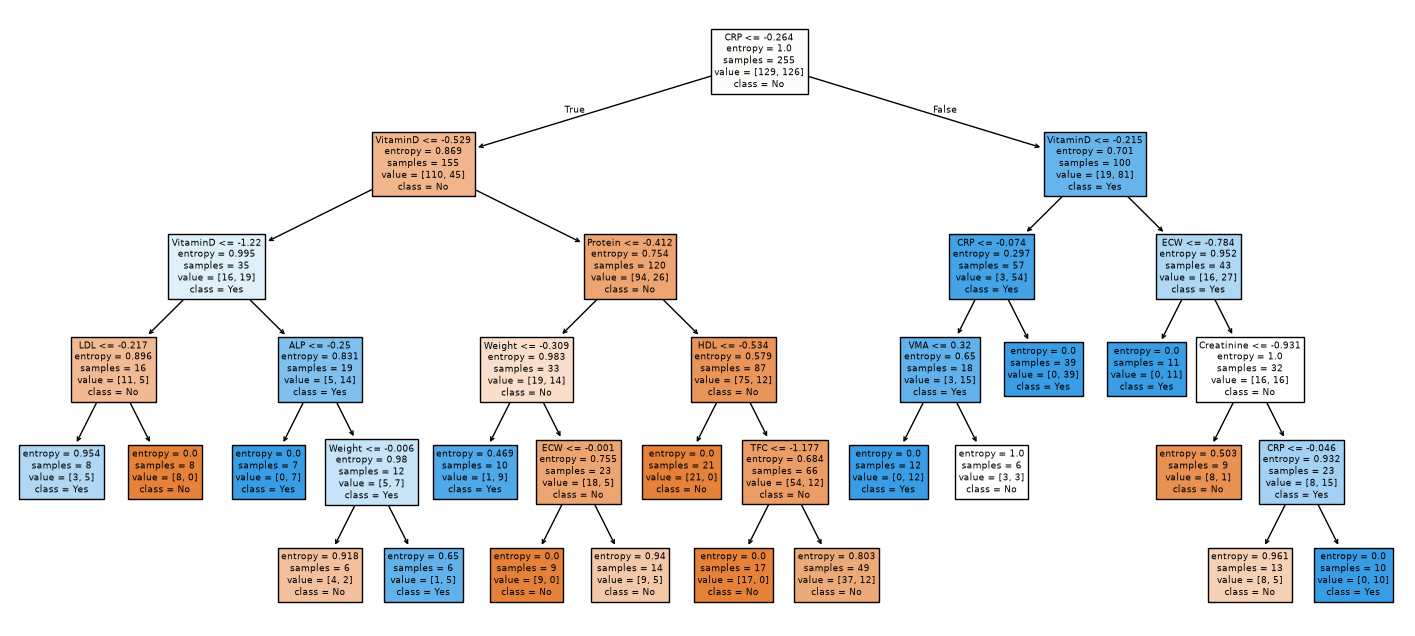

In [39]:
# Decision Tree

#cross validation for fair testing
cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#grid for pre-pruning tree before training
pre_prune_parameters_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best'],
    'max_depth': [3, 5, 7, 10, 15, 20, 25],
    'min_samples_split': [2, 3, 4, 5, 6, 7, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 10]
}

#grid search for pre-pruning parameters
pre_prune_grid = GridSearchCV(
    estimator = DecisionTreeClassifier(random_state=42),
    param_grid = pre_prune_parameters_grid,
    scoring = 'balanced_accuracy',
    cv = cross_validation
)

# get candidate alphas for post-pruning of tree
post_prune_tree= DecisionTreeClassifier(random_state=42)
path_cost = post_prune_tree.cost_complexity_pruning_path(X_train_scaled, y_train)
alpha_candidates, impurities = path_cost.ccp_alphas, path_cost.impurities

#grid for post-prune search
post_prune_parameters_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best'],
    'ccp_alpha': alpha_candidates
}

#grid search for post-pruning parameters
post_prune_grid = GridSearchCV(
    estimator = DecisionTreeClassifier(random_state=42),
    param_grid = post_prune_parameters_grid,
    scoring = 'balanced_accuracy',
    cv = cross_validation
)

#fit both grid searches to training data
pre_prune_grid.fit(X_train_scaled, y_train)
post_prune_grid.fit(X_train_scaled, y_train)

#compare results of both grid searches and sort by best balanced accuracy
compare_results = pd.DataFrame([{
    "model": "pre_prune",
    "best_cv_balanced_accuracy": pre_prune_grid.best_score_,
    "best_params": pre_prune_grid.best_params_
    },
    {
    "model": "post_prune",
    "best_cv_balanced_accuracy": post_prune_grid.best_score_,
    "best_params": post_prune_grid.best_params_
    }
]).sort_values("best_cv_balanced_accuracy", ascending=False)
#display results
display(compare_results)

#compare results
if pre_prune_grid.best_score_ > post_prune_grid.best_score_:
    best_name = "pre_prune"
    best_search = pre_prune_grid
else:
    best_name = "post_prune"
    best_search = post_prune_grid
#based of comparison select best model and use to predict on test set
best_tree = best_search.best_estimator_
y_pred = best_tree.predict(X_test_scaled)

#print results, which is best model (pre/post-prune), print results of best model, and
# display parameters of best model
print("Best overall approach:", best_name)
print("Best CV balanced accuracy: ", best_search.best_score_)
print("Best parameters:", best_search.best_params_)

#print final test results for winner model
print("Best accuracy: ", accuracy_score(y_test, y_pred))
print("Best balanced accuracy: ", balanced_accuracy_score(y_test, y_pred))
print("Best F1 score: ", f1_score(y_test, y_pred, zero_division=0))

#display feature importance for best tree model
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": best_tree.feature_importances_
}).sort_values("importance", ascending=False)
display(feature_importance)

#plot tree for best model
plt.figure(figsize=(18, 8))
plot_tree(best_tree, filled=True, feature_names=features, class_names=['No', 'Yes'])
plt.show()